In [ ]:
# compute and plot FATES and observed diurnal sapflow at BIONTE

In [ ]:
import os
import dask
from dask.distributed import Client, LocalCluster

# Point Dask to the fast NERSC Scratch file system
scratch_dir = os.environ.get('SCRATCH', '/tmp')
cluster = LocalCluster(local_directory=f"{scratch_dir}/dask-worker-space")
client = Client(cluster)


In [ ]:
#client

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
#
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
# 
import gc # garbage collection


ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 14
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures


In [3]:
days_per_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
nyears = 25

In [ ]:
###################################################################
###################################################################
## Extract and save FATES sapflow #################################

In [ ]:
tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'

file1=tag+'.elm.h1.01.cat.nc'
file2=tag+'.elm.h1.02.cat.nc'
file3=tag+'.elm.h1.03.cat.nc'
file4=tag+'.elm.h1.04.cat.nc'
file5=tag+'.elm.h1.05.cat.nc'
file6=tag+'.elm.h1.06.cat.nc'
file7=tag+'.elm.h1.07.cat.nc'
file8=tag+'.elm.h1.08.cat.nc'
file9=tag+'.elm.h1.09.cat.nc'
file10=tag+'.elm.h1.10.cat.nc'
file11=tag+'.elm.h1.11.cat.nc'
file12=tag+'.elm.h1.12.cat.nc'

chunk_size=100
d1 = xr.open_dataset(path+file1,chunks={'time': chunk_size})
d2 = xr.open_dataset(path+file2,chunks={'time': chunk_size})
d3 = xr.open_dataset(path+file3,chunks={'time': chunk_size})
d4 = xr.open_dataset(path+file4,chunks={'time': chunk_size})
d5 = xr.open_dataset(path+file5,chunks={'time': chunk_size})
d6 = xr.open_dataset(path+file6,chunks={'time': chunk_size})
d7 = xr.open_dataset(path+file7,chunks={'time': chunk_size})
d8 = xr.open_dataset(path+file8,chunks={'time': chunk_size})
d9 = xr.open_dataset(path+file9,chunks={'time': chunk_size})
d10 = xr.open_dataset(path+file10,chunks={'time': chunk_size})
d11 = xr.open_dataset(path+file11,chunks={'time': chunk_size})
d12 = xr.open_dataset(path+file12,chunks={'time': chunk_size})

In [ ]:
sapflow_raw1=fa.scpf_to_scls_by_pft(d1.FATES_SAPFLOW_SZPF,d1)
sapflow_raw2=fa.scpf_to_scls_by_pft(d2.FATES_SAPFLOW_SZPF,d2)
sapflow_raw3=fa.scpf_to_scls_by_pft(d3.FATES_SAPFLOW_SZPF,d3)
sapflow_raw4=fa.scpf_to_scls_by_pft(d4.FATES_SAPFLOW_SZPF,d4)
sapflow_raw5=fa.scpf_to_scls_by_pft(d5.FATES_SAPFLOW_SZPF,d5)
sapflow_raw6=fa.scpf_to_scls_by_pft(d6.FATES_SAPFLOW_SZPF,d6)
sapflow_raw7=fa.scpf_to_scls_by_pft(d7.FATES_SAPFLOW_SZPF,d7)
sapflow_raw8=fa.scpf_to_scls_by_pft(d8.FATES_SAPFLOW_SZPF,d8)
sapflow_raw9=fa.scpf_to_scls_by_pft(d9.FATES_SAPFLOW_SZPF,d9)
sapflow_raw10=fa.scpf_to_scls_by_pft(d10.FATES_SAPFLOW_SZPF,d10)
sapflow_raw11=fa.scpf_to_scls_by_pft(d11.FATES_SAPFLOW_SZPF,d11)
sapflow_raw12=fa.scpf_to_scls_by_pft(d12.FATES_SAPFLOW_SZPF,d12)

In [ ]:
sapwood_area1=fa.scpf_to_scls_by_pft(d1.FATES_SAPWOOD_AREA_SZPF,d1)
sapwood_area2=fa.scpf_to_scls_by_pft(d2.FATES_SAPWOOD_AREA_SZPF,d2)
sapwood_area3=fa.scpf_to_scls_by_pft(d3.FATES_SAPWOOD_AREA_SZPF,d3)
sapwood_area4=fa.scpf_to_scls_by_pft(d4.FATES_SAPWOOD_AREA_SZPF,d4)
sapwood_area5=fa.scpf_to_scls_by_pft(d5.FATES_SAPWOOD_AREA_SZPF,d5)
sapwood_area6=fa.scpf_to_scls_by_pft(d6.FATES_SAPWOOD_AREA_SZPF,d6)
sapwood_area7=fa.scpf_to_scls_by_pft(d7.FATES_SAPWOOD_AREA_SZPF,d7)
sapwood_area8=fa.scpf_to_scls_by_pft(d8.FATES_SAPWOOD_AREA_SZPF,d8)
sapwood_area9=fa.scpf_to_scls_by_pft(d9.FATES_SAPWOOD_AREA_SZPF,d9)
sapwood_area10=fa.scpf_to_scls_by_pft(d10.FATES_SAPWOOD_AREA_SZPF,d10)
sapwood_area11=fa.scpf_to_scls_by_pft(d11.FATES_SAPWOOD_AREA_SZPF,d11)
sapwood_area12=fa.scpf_to_scls_by_pft(d12.FATES_SAPWOOD_AREA_SZPF,d12)

In [ ]:
## Extract and average over 3x3 grid centered on BIONTE

bionte_lat, bionte_lon = -2.6, 360.0 - 60.2  # = 299.8
lat_idx = np.argmin(np.abs(d1.lat.values - bionte_lat))
lon_idx = np.argmin(np.abs(d1.lon.values - bionte_lon))
lat_slice = slice(lat_idx - 1, lat_idx + 2)
lon_slice = slice(lon_idx - 1, lon_idx + 2)

In [ ]:
sapflow1=sapflow_raw1.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area1.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow2=sapflow_raw2.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area2.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow3=sapflow_raw3.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area3.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow4=sapflow_raw4.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area4.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow5=sapflow_raw5.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area5.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow6=sapflow_raw6.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area6.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow7=sapflow_raw7.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area7.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow8=sapflow_raw8.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area8.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow9=sapflow_raw9.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area9.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow10=sapflow_raw10.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area10.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow11=sapflow_raw11.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area11.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))
sapflow12=sapflow_raw12.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area12.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))

In [ ]:
import gc
del sapflow_raw1, sapflow_raw2, sapflow_raw3, sapflow_raw4, sapflow_raw5, sapflow_raw6
del sapflow_raw7, sapflow_raw8, sapflow_raw9, sapflow_raw10, sapflow_raw11, sapflow_raw12
del sapwood_area1, sapwood_area2, sapwood_area3, sapwood_area4, sapwood_area5, sapwood_area6
del sapwood_area7, sapwood_area8, sapwood_area9, sapwood_area10, sapwood_area11, sapwood_area12
gc.collect()  # Force cleanup


In [ ]:
# Put sapflow DataArrays and days per month into lists
sapflows = [
    sapflow1, sapflow2, sapflow3, sapflow4, sapflow5, sapflow6,
    sapflow7, sapflow8, sapflow9, sapflow10, sapflow11, sapflow12
]

In [ ]:
# 1. Slice the DataArrays lazily (DO NOT call .values yet)
lazy_diurnals = []
for sapflow_da, ndays in zip(sapflows, days_per_month):
    ndays_tot = int(ndays * nyears)
    sliced_da = sapflow_da.isel(time=slice(0, ndays_tot * 24))
    lazy_diurnals.append(sliced_da)

In [ ]:
# 2. Compute all 12 months at once in parallel
# Dask will optimize the graph and process everything much faster
computed_diurnals = dask.compute(*lazy_diurnals)

In [ ]:
computed_diurnals[0].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Jan.nc')
computed_diurnals[1].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Feb.nc')
computed_diurnals[2].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Mar.nc')
computed_diurnals[3].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Apr.nc')
computed_diurnals[4].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_May.nc')
computed_diurnals[5].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Jun.nc')
computed_diurnals[6].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Jul.nc')
computed_diurnals[7].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Aug.nc')
computed_diurnals[8].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Sep.nc')
computed_diurnals[9].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Oct.nc')
computed_diurnals[10].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Nov.nc')
computed_diurnals[11].to_netcdf('/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_computed_diurnals_Dec.nc')


In [ ]:
###################################################################
###################################################################

In [67]:
size_classes = {
    0: {'label': '0-5', 'min_dbh': 0, 'max_dbh': 5},
    1: {'label': '5-10', 'min_dbh': 5, 'max_dbh': 10},
    2: {'label': '10-15', 'min_dbh': 10, 'max_dbh': 15},
    3: {'label': '15-20', 'min_dbh': 15, 'max_dbh': 20},
    4: {'label': '20-30', 'min_dbh': 20, 'max_dbh': 30},
    5: {'label': '30-40', 'min_dbh': 30, 'max_dbh': 40},
    6: {'label': '40-50', 'min_dbh': 40, 'max_dbh': 50},
    7: {'label': '50-60', 'min_dbh': 50, 'max_dbh': 60},
    8: {'label': '60-70', 'min_dbh': 60, 'max_dbh': 70},
    9: {'label': '70-80', 'min_dbh': 70, 'max_dbh': 85}  # Note: on tree in BIONTE > 80 cm DBH, is 82.2
}

In [68]:
def compute_quartiles(diurnal_array):
    """
    Compute median and quartiles over the day axis
    Input: (ndays, hours, pft, scls)
    Output: (24, 2, 13) - collapsed over days
    """
    med = np.nanmedian(diurnal_array, axis=0)  # axis=0 is the day axis
    mean = np.nanmean(diurnal_array, axis=0)
    low = np.nanquantile(diurnal_array, 0.25, axis=0)
    hi = np.nanquantile(diurnal_array, 0.75, axis=0)
    
    return med, mean, low, hi


In [69]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
base_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FATES_output/FATES_computed_diurnals_'

computed_diurnals = []
for month in month_names:
    file_path = f'{base_path}{month}.nc'
    da = xr.open_dataarray(file_path)
    computed_diurnals.append(da)

In [70]:
# 3. Reshape the evaluated arrays and compute quartiles immediately
med_list, mean_list, low_list, hi_list = [], [], [], []

for comp_da, ndays in zip(computed_diurnals, days_per_month):
    ndays_tot = int(ndays * nyears)
    # Note: we can use the numpy array directly here since it's already computed
    reshaped_array = comp_da.values.reshape(ndays_tot, 24, 2, 13)
    
    # Compute the quartiles directly
    med, mean, low, hi = compute_quartiles(reshaped_array)
    med_list.append(med)
    mean_list.append(mean)
    low_list.append(low)
    hi_list.append(hi)

/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/tmp/ipykernel_1355496/703277539.py:8: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(diurnal_array, axis=0)
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


In [71]:
## read in BIONTE sapflow data
# From Yilin (1/24/25): units are g/cm2/h.
bionte_sapflow_csv='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FromYilin/Js_All_2022_2023.csv'

# Load the data
bionte_sapflow_data = pd.read_csv(bionte_sapflow_csv)

# Quick look at the first few rows
print(bionte_sapflow_data.head())

# Check the data types to ensure numbers are floats
print(bionte_sapflow_data.info())


   year  doy  hour        s1        s2        s3        s4        s5  \
0  2022  166     0  0.128901  0.112743  0.067446  0.062562  0.000000   
1  2022  166    30  0.106871  0.087761  0.067446  0.056789  0.013450   
2  2022  166   100  0.088653  0.075786  0.035871  0.051127  0.020042   
3  2022  166   130  0.091402  0.064167  0.035871  0.036955  0.049972   
4  2022  166   200  0.057151  0.048553  0.021747  0.035918  0.062793   

         s6        s7  ...      s108      s109  s110      s111      s112  \
0  1.406247  0.027376  ...  0.314723  0.000950   NaN  0.035787  0.003227   
1  1.401277  0.004100  ...  0.272274  0.006709   NaN  0.039196  0.003321   
2  1.403414  0.004100  ...  0.208762  0.011583   NaN  0.028612  0.006194   
3  1.419786  0.007692  ...  0.174265  0.014808   NaN  0.018740  0.007709   
4  1.436193  0.004100  ...  0.149335  0.008170   NaN  0.025014  0.016367   

   s113      s114      s115      s116      s117  
0   0.0  0.284942  0.000000  0.064725  0.059820  
1   0.0  0

In [72]:
bionte_sapflow_data['date'] = pd.to_datetime(bionte_sapflow_data['year'].astype(str) + bionte_sapflow_data['doy'].astype(str), format='%Y%j')
bionte_sapflow_data['month'] = bionte_sapflow_data['date'].dt.month
# Drop the temporary 'date' column if it's not needed further
bionte_sapflow_data = bionte_sapflow_data.drop(columns=['date'])

print(bionte_sapflow_data[['year', 'doy', 'month']].head())

   year  doy  month
0  2022  166      6
1  2022  166      6
2  2022  166      6
3  2022  166      6
4  2022  166      6


In [73]:
# Add 'decimal_hour' column to bionte_sapflow_data if it doesn't exist
# This converts the 'HHMM' formatted 'hour' column to a decimal representation (e.g., 0.0, 0.5, 1.0)
if 'decimal_hour' not in bionte_sapflow_data.columns:
    bionte_sapflow_data['decimal_hour'] = (
        bionte_sapflow_data['hour'] // 100
    ) + (
        bionte_sapflow_data['hour'] % 100
    ) / 60

def get_median_diurnal_sapflow(target_month, sensor_list):
    """
    Calculates the median, 25th, and 75th percentiles of the diurnal cycle of sapflow
    for a given month and list of sensors.

    Args:
        target_month (int): The month number (1-12) to filter the data.
        sensor_list (list): A list of strings representing the sensor columns (e.g., ['s1', 's2']).

    Returns:
        pandas.DataFrame: A DataFrame containing the median, 25th percentile (q25),
                          and 75th percentile (q75) of sapflow for each 'decimal_hour'.
                          Index will be 'decimal_hour'. Returns an empty DataFrame if no data.
    """
    # Filter data for the target month. Use .copy() to prevent SettingWithCopyWarning.
    monthly_data = bionte_sapflow_data[bionte_sapflow_data['month'] == target_month].copy()

    if monthly_data.empty:
        print(f"No data found for month {target_month}.")
        return pd.DataFrame(dtype=float)

    # Ensure all requested sensor_list columns exist in the monthly_data
    existing_sensors = [s for s in sensor_list if s in monthly_data.columns]
    if not existing_sensors:
        print(f"None of the requested sensors {sensor_list} found in data for month {target_month}.")
        return pd.DataFrame(dtype=float)

    # Select the relevant sensor columns and the 'decimal_hour'
    columns_to_select = ['decimal_hour'] + existing_sensors
    selected_data = monthly_data[columns_to_select]

    # Melt the sensor columns into a single 'sapflow_value' column
    # This stacks all sapflow values from the selected sensors into one column
    melted_data = selected_data.melt(id_vars=['decimal_hour'],
                                     value_vars=existing_sensors,
                                     var_name='sensor_id',
                                     value_name='sapflow_value')

    # Exclude sapflow values that are exactly 0
    melted_data = melted_data[melted_data['sapflow_value'] > 0]

    # Group by 'decimal_hour' and calculate median, 25th, and 75th quantiles
    diurnal_stats = melted_data.groupby('decimal_hour')['sapflow_value'].agg(
        mean='mean',
        median='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )

    return diurnal_stats


In [74]:
# read in wood density etc

bionte_info_csv='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FromYilin/Abstract_Bionte.csv'
bionte_info = pd.read_csv(bionte_info_csv)


In [75]:
bionte_info

,Plot,ID,Sensor_TRUE,sensor,species,genus,DBH,HT,WD,profund,active_xylem,Js_wet22,Js_dry22,Js_wet23,Js_elnino,Wood_Density,mortality_mean,rate_mort
0,B4,003X,ss1,s1,Andira.parviflora,Andira,25.5,24.55,0.62,2cm,249.793842,11.884893,13.249132,2.555995,3.697901,Medium,0.004310,0.431034
1,B4,277F,ss2,s2,Tachigali.melanocarpa,Tachigali,76.5,39.55,0.55,2cm,1059.835091,4.984088,5.668813,14.087227,14.872871,Medium,0.006897,0.689655
2,B4,177,ss3,s3,Qualea.paraensis,Qualea,55.0,26.55,0.55,2cm,678.426629,4.553347,5.781519,14.284233,13.310860,Medium,0.028736,2.873563
3,B4,176,ss4,s4,Duckeodendron.cestroides,Duckeodendron,62.3,17.55,0.69,2cm,2646.291721,0.307542,0.148132,2.195696,3.120952,Medium,0.007280,0.727969
4,B4,176YC,ss5,s5,Vismia.guianensis,Vismia,16.7,16.55,0.40,2cm,122.243651,5.833225,4.947400,2.957329,2.597320,Low,0.051724,5.172414
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,B1,314,ss35,s113,Micrandropsis.scleroxylon,Micrandropsis,44.6,22.55,0.62,4cm,647.580951,2.044276,2.041726,1.832219,0.970468,Medium,0.003472,0.347206
113,B1,313L,ss36,s114,Croton.matourensis,Croton,26.3,27.55,0.66,4cm,268.059345,16.282766,17.929343,14.022134,11.642581,Medium,0.021707,2.170660
114,B1,324J,ss37,s115,Pourouma.bicolor,Pourouma,28.7,24.35,0.32,4cm,310.147024,4.336374,7.040505,3.070257,2.603486,Low,0.009552,0.955173
115,B1,324M,ss38,s116,Pourouma.tomentosa,Pourouma,26.6,23.35,0.32,4cm,273.185211,0.549286,0.757278,1.013067,0.604741,Low,0.009200,0.919972


In [76]:
len(np.unique(bionte_info.ID))

87

In [77]:
len(np.unique(bionte_info.sensor))

117

In [78]:
def get_sensors_by_dbh_class(class_idx):
    """
    Selects sensor values from bionte_info based on the provided DBH size class index.

    Args:
        class_idx (int): The index of the size class (e.g., 0 for '0-5', 1 for '5-10').

    Returns:
        pandas.Series: A Series of sensor IDs (e.g., 's1', 's2') that fall within
                       the specified DBH size class. Returns an empty Series if no
                       sensors match the criteria.
    """
    if class_idx not in size_classes:
        print(f"Error: class_idx {class_idx} not found in size_classes.")
        return pd.Series(dtype=str)

    conf = size_classes[class_idx]
    min_dbh = conf['min_dbh']
    max_dbh = conf['max_dbh']

    # Filter bionte_info based on DBH
    # Assuming bionte_info has a 'DBH' column and a 'sensor' column
    filtered_sensors = bionte_info[
        (bionte_info['DBH'] >= min_dbh) &
        (bionte_info['DBH'] < max_dbh)
    ]['sensor']

    return filtered_sensors

In [79]:
def get_ID_by_dbh_class(class_idx):
    if class_idx not in size_classes:
        print(f"Error: class_idx {class_idx} not found in size_classes.")
        return pd.Series(dtype=str)

    conf = size_classes[class_idx]
    min_dbh = conf['min_dbh']
    max_dbh = conf['max_dbh']

    filtered_IDs = bionte_info[
        (bionte_info['DBH'] >= min_dbh) &
        (bionte_info['DBH'] < max_dbh)
    ]['ID']

    return filtered_IDs

In [80]:
hours = np.arange(24)
hours2=np.arange(48)/2.
month_labels = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']
site_dt=-4

# convert from kg/m^2/s to g/cm^2/hr

cf=1000*3600/(100**2)

# density of water is 1 g/cm^3
# g/cm^2/hr * (1/density of water) = sap velocity in cm/hr

In [81]:
def plot_diurnal_sapflow(med_list, low_list, hi_list, size_classes,
                         scls_ind, y_min=-2, y_max=17):

    textx, texty = 17, y_max * 0.9

    plt.rcParams['lines.linewidth'] = 2
    fig = plt.figure(figsize=(16, 8))
    fig.text(0.22, 0.9,
             'Early PFT (green), late PFT (blue), observed (orange)',
             fontsize=20)

    axes = fig.subplots(2, 6, sharex='col', sharey='row')

    for m, ax in enumerate(axes.flat):
        month = m + 1

        # early PFT
        mean_mod = np.roll(cf * mean_list[m][:, 0, scls_ind], site_dt)
        low_mod = np.roll(cf * low_list[m][:, 0, scls_ind], site_dt)
        hi_mod  = np.roll(cf *  hi_list[m][:, 0, scls_ind], site_dt)

        ax.plot(hours, mean_mod, color="green")
        ax.fill_between(hours, low_mod, hi_mod, color="green", alpha=0.2)

        # late PFT
        mean_mod = np.roll(cf * mean_list[m][:, 1, scls_ind], site_dt) 
        low_mod = np.roll(cf * low_list[m][:, 1, scls_ind], site_dt)
        hi_mod  = np.roll(cf *  hi_list[m][:, 1, scls_ind], site_dt)

        ax.plot(hours, mean_mod, color="blue")
        ax.fill_between(hours, low_mod, hi_mod, color="blue", alpha=0.2)

        # observed
        sensors = get_sensors_by_dbh_class(scls_ind).tolist()
        stats = get_median_diurnal_sapflow(month, sensors)
        
        filtered_IDs = get_ID_by_dbh_class(scls_ind).tolist()
        num_trees=len(np.unique(filtered_IDs))

        ax.plot(hours2, stats['mean'], color='orangered')
        ax.fill_between(hours2, stats['q25'], stats['q75'], color='orangered', alpha=0.2)

        ax.text(textx, texty, month_labels[m], fontsize=12)
        ax.set_xlim(0, 24)
        ax.set_ylim(y_min, y_max)
        ax.label_outer()

    plt.suptitle('BIONTE sapflow (DBH ' + size_classes[scls_ind]['label']+ ' cm, ' + str(num_trees) + ' trees)\n', fontsize=30)

    plt.tight_layout(w_pad=1, h_pad=1)
    fig.supxlabel('Hour (local time)', fontsize=24)
    fig.supylabel('sapflow (g/cm$^2$/hr)', fontsize=24)
    fig.subplots_adjust(left=0.08, bottom=0.10)
    plt.show()

/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


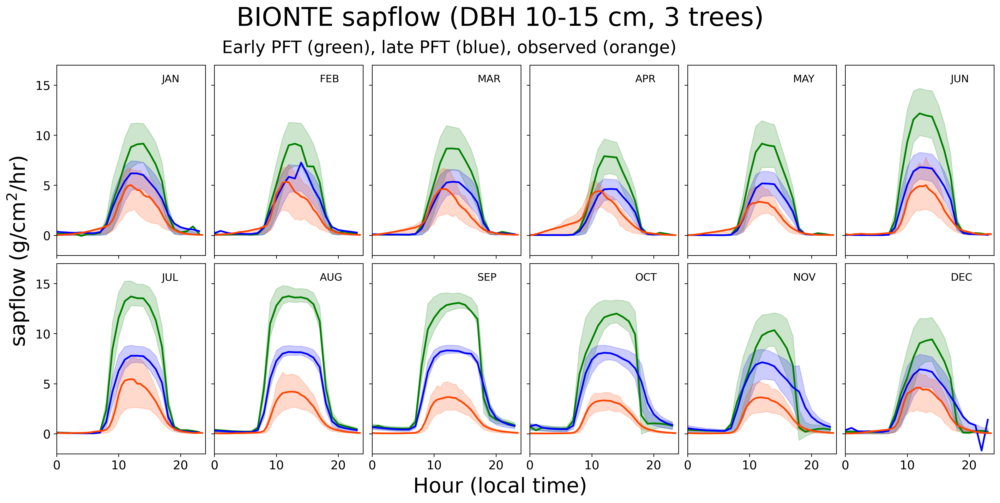

In [82]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=2)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


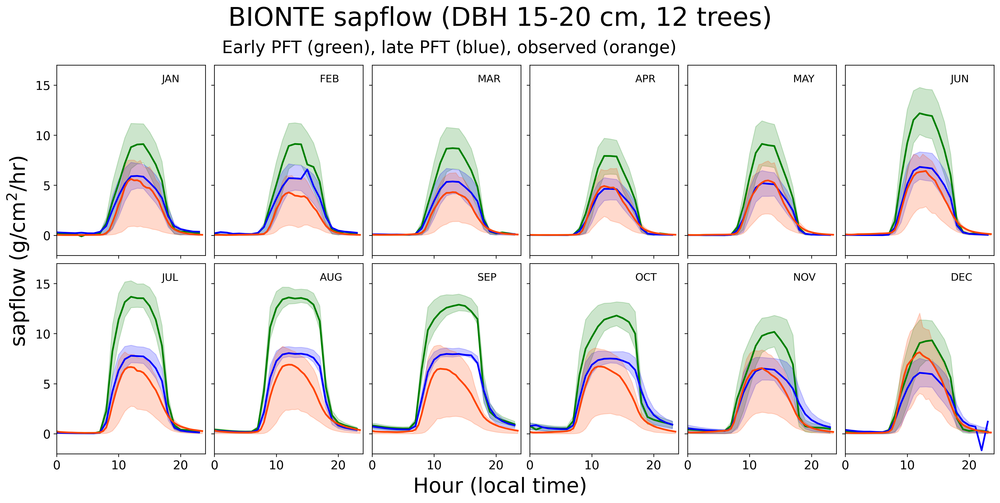

In [83]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=3)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


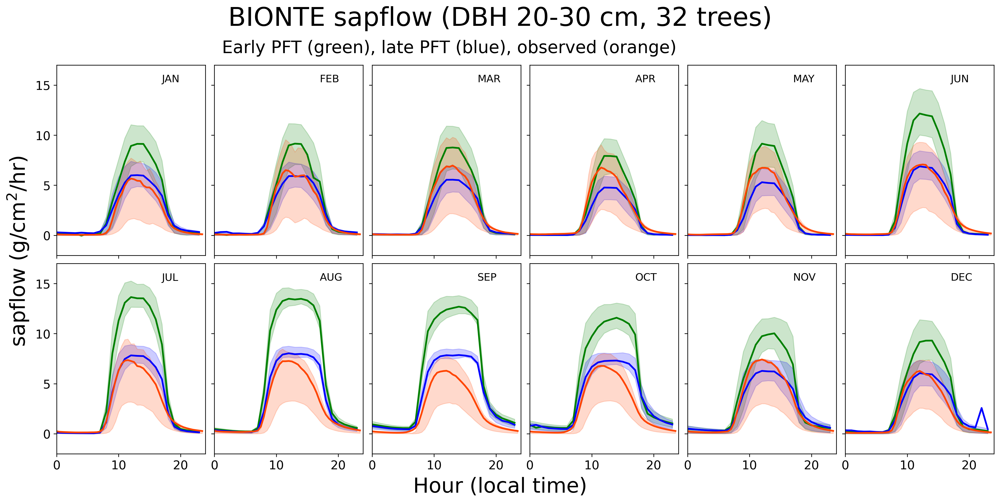

In [84]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=4)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


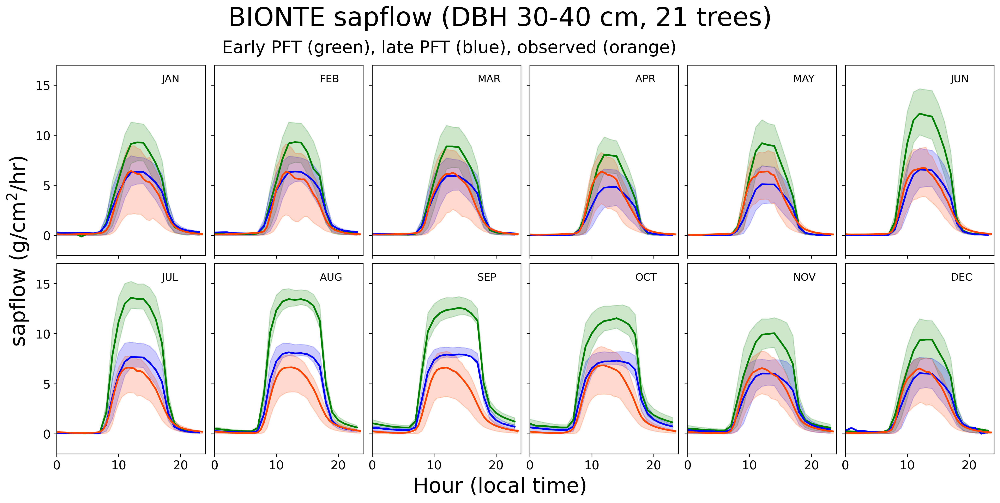

In [85]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=5)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


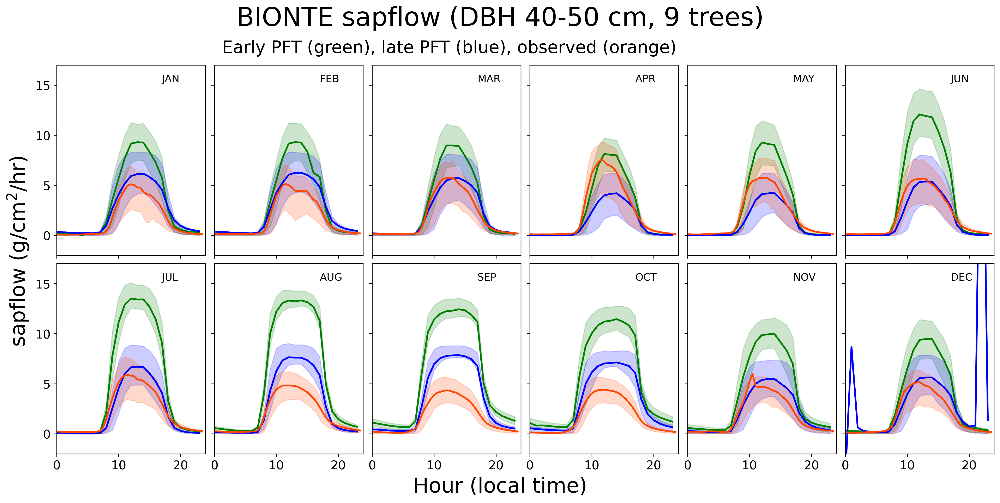

In [86]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=6)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


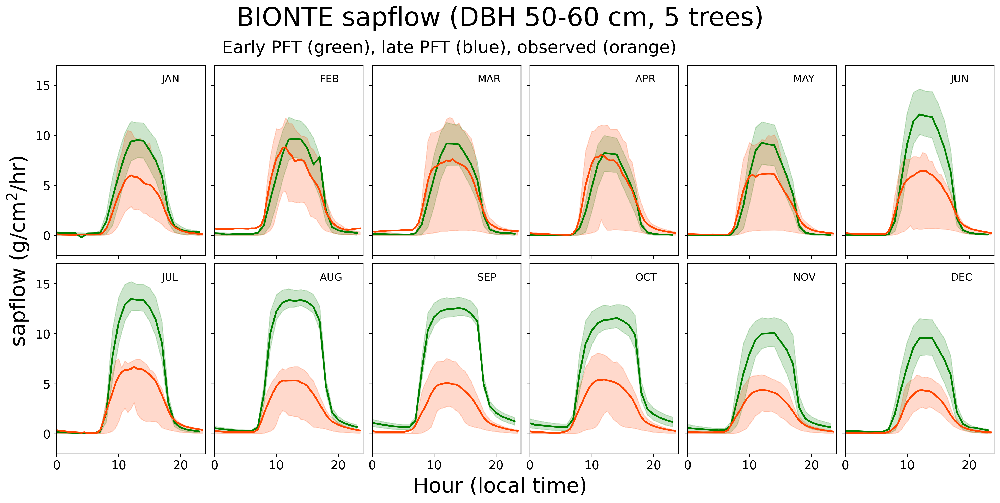

In [87]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=7)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


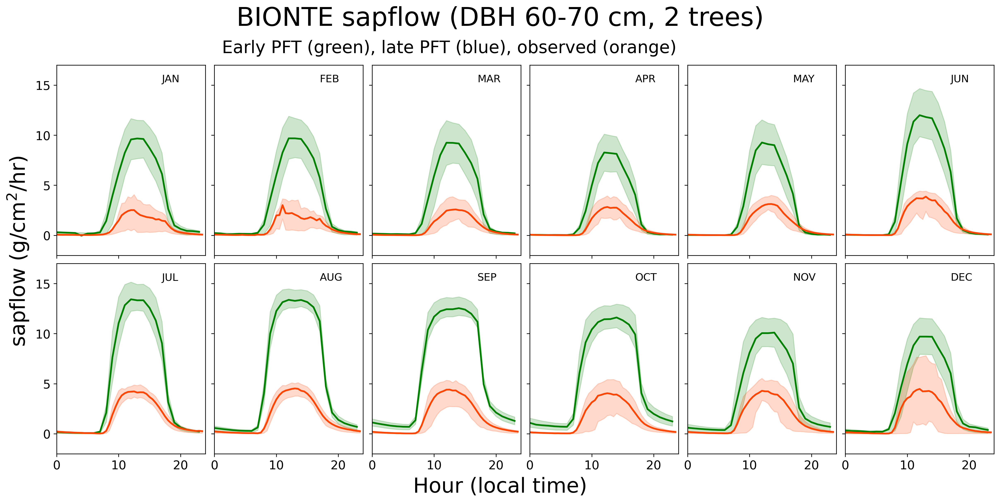

In [88]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=8)


/tmp/ipykernel_1355496/807344861.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(w_pad=1, h_pad=1)
/tmp/ipykernel_1355496/807344861.py:53: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=0.08, bottom=0.10)


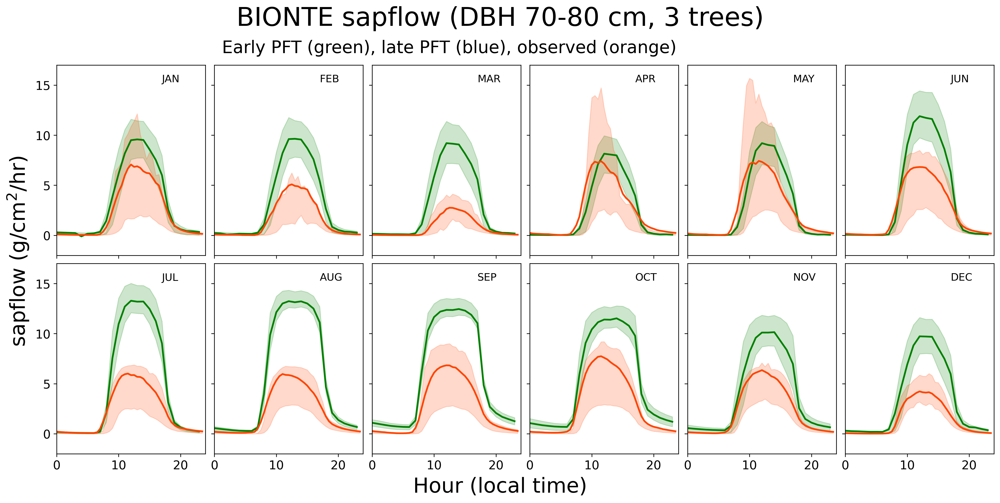

In [89]:
plot_diurnal_sapflow(mean_list, low_list, hi_list, size_classes, scls_ind=9)
